# Practice 3 — Hugging Face: Sentiment Analysis & Fine-tuning

**Report notebook (read-only):** loads locally produced artifacts. It **does not download a model, execute training or generate fabricated results**. Run scripts first.

**Student:** [fill in] · **Date:** [fill in] · **Run:** `lan_1` (edit below).


## 1. Aim and acceptance checklist

**Exercise 1:** install Transformers, pretrained Hub sentiment classifier, tokenization and prediction. **Exercise 2:** install Transformers/Datasets/Evaluate, IMDb data, tokenizer/model, preprocessing, TrainingArguments, Trainer fine-tuning and final evaluation.

Data split: train/validation from official IMDb train, reserved test from official IMDb test. See `Experiment_Plan.md` and `docs/`.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Markdown, Image

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    candidate = ROOT / "practice_3_huggingface"
    if candidate.exists(): ROOT = candidate
RUN = 'lan_1'  # change to your completed run
run = ROOT / 'outputs' / 'runs' / RUN

def read_json(path):
    return json.loads(path.read_text(encoding='utf-8')) if path.exists() else None

print('Practice root:', ROOT.resolve())
print('Run:', RUN, '| Complete:', (run / 'TRAINING_COMPLETE').exists())


Practice root: /Users/tranhuynh/Documents/DL/practice_3_huggingface
Run: lan_1 | Complete: True


## 2. Exercise 1 — model, tokens, inference

A pretrained sentiment classifier performs **inference**; it does not update weights. Show exact input, tokens, token IDs and model response. Scores are model predictions, not calibrated guarantees.

In [2]:
ex1 = read_json(ROOT / 'outputs' / 'exercise1' / 'sentiment_result.json')
if ex1 is None:
    print('Exercise 1 artifact absent. Run src/1_sentiment.py first.')
else:
    for key in ['model_id','sentence','tokens','token_ids','predicted_label','model_score']:
        print(f'{key}: {ex1.get(key)}')


model_id: distilbert/distilbert-base-uncased-finetuned-sst-2-english
sentence: The film started slowly, but I absolutely loved its ending.
tokens: ['the', 'film', 'started', 'slowly', ',', 'but', 'i', 'absolutely', 'loved', 'its', 'ending', '.']
token_ids: [101, 1996, 2143, 2318, 3254, 1010, 2021, 1045, 7078, 3866, 2049, 4566, 1012, 102]
predicted_label: POSITIVE
model_score: 0.9998162388801575


## 3. Dataset, labels and split integrity

The only labeled classes are 0=NEGATIVE and 1=POSITIVE. Report selected subset counts and SHA256; test is not used for checkpoint selection.

In [3]:
split = read_json(ROOT / 'outputs' / 'data' / 'split_info.json')
if split is None:
    print('No prepared data. Run src/2_preparedata.py.')
else:
    print('Dataset:', split.get('dataset_id'))
    print('Seed:', split.get('seed'), 'Max length:', split.get('max_length'))
    display(pd.DataFrame([{'split':k, **v['labels'], 'n':v['count'], 'sha256':v['text_label_sha256'][:16]+'…'}
                          for k,v in split['splits'].items()]))


Dataset: stanfordnlp/imdb
Seed: 42 Max length: 128


,split,NEGATIVE,POSITIVE,n,sha256
0,train,993,1007,2000,4699197586d4371c…
1,validation,199,201,400,e768f624b5d2ce07…
2,test,254,246,500,4b9e8123673e9a5f…


## 4. Fine-tuning configuration and selected run

Fine-tune `distilbert-base-uncased` for binary classification. A new head emits two logits per review, and Trainer handles forward, cross entropy, backward and optimizer steps.

In [4]:
cfg = read_json(run / 'config.json')
if cfg is None:
    print('No configuration found. Training may not have started.')
else:
    for k in ('base_model','dataset_id','seed','train_samples','validation_samples','max_length',
              'epochs','batch_size','learning_rate','weight_decay','best_checkpoint','best_metric'):
        print(f'{k}: {cfg.get(k, "not recorded")}')


base_model: distilbert/distilbert-base-uncased
dataset_id: stanfordnlp/imdb
seed: 42
train_samples: 2000
validation_samples: 400
max_length: 128
epochs: 3
batch_size: 8
learning_rate: 2e-05
weight_decay: 0.01
best_checkpoint: /Users/tranhuynh/Documents/DL/practice_3_huggingface/outputs/runs/lan_1/checkpoints/checkpoint-500
best_metric: 0.8668280871670703


## 5. Train and validation evidence

Read the actual Trainer history and run summaries. Empty outputs mean **not measured**, not zero. Differentiate training and validation losses.

In [5]:
history = read_json(run / 'history.json')
if history is None:
    print('history.json absent. No completed training history to report.')
else:
    interesting = ['epoch','step','loss','eval_loss','eval_accuracy','eval_precision','eval_recall','eval_f1','learning_rate']
    table = pd.DataFrame(history)
    display(table[[c for c in interesting if c in table.columns]].tail(20))
    print('Actual history rows:',len(table))
print('Training:', read_json(run / 'train_metrics.json'))
print('Validation:', read_json(run / 'validation_metrics.json'))


,epoch,step,loss,eval_loss,eval_accuracy,eval_precision,eval_recall,eval_f1,learning_rate
0,1.0,250,0.521874,NaN,NaN,NaN,NaN,NaN,1.336000e-05
1,1.0,250,NaN,0.421360,0.8250,0.767347,0.935323,0.843049,NaN
2,2.0,500,0.287904,NaN,NaN,NaN,NaN,NaN,6.693333e-06
3,2.0,500,NaN,0.408872,0.8625,0.844340,0.890547,0.866828,NaN
4,3.0,750,0.161140,NaN,NaN,NaN,NaN,NaN,2.666667e-08
5,3.0,750,NaN,0.522794,0.8575,0.860000,0.855721,0.857855,NaN
6,3.0,750,NaN,NaN,NaN,NaN,NaN,NaN,NaN
7,3.0,750,NaN,0.408872,0.8625,0.844340,0.890547,0.866828,NaN


Actual history rows: 8
Training: {'train_runtime': 227.4379, 'train_samples_per_second': 26.381, 'train_steps_per_second': 3.298, 'total_flos': 198701097984000.0, 'train_loss': 0.3236394348144531, 'epoch': 3.0}
Validation: {'eval_loss': 0.4088723361492157, 'eval_accuracy': 0.8625, 'eval_precision': 0.8443396226415094, 'eval_recall': 0.8905472636815921, 'eval_f1': 0.8668280871670703, 'eval_runtime': 2.0783, 'eval_samples_per_second': 192.466, 'eval_steps_per_second': 24.058, 'epoch': 3.0}


## 6. Final independent evaluation

`validation_recheck.json` is not the same as `test_metrics.json`. The final test should be run once after selection is frozen, and evidence must identify the split.

In [6]:
test = read_json(run / 'test_metrics.json')
val = read_json(run / 'validation_recheck.json')
evidence = test if test is not None else val
if evidence is None:
    print('No prediction-level evaluation. Run 4_evaluate.py on validation first.')
else:
    print('Split:', evidence.get('split'), '| count:', evidence.get('sample_count'))
    display(pd.Series(evidence.get('metrics', {}),name='metric').to_frame())
    print('ROC-AUC:',evidence.get('roc_auc'))
    if evidence.get('classification_report'):
        display(pd.DataFrame(evidence['classification_report']).T)
    print('Confusion matrix (rows actual; columns predicted):',evidence.get('confusion_matrix'))


Split: test | count: 500


,metric
test_loss,0.475887
test_model_preparation_time,0.000700
test_accuracy,0.840000
test_precision,0.794326
test_recall,0.910569
test_f1,0.848485
test_runtime,9.877600
test_samples_per_second,50.619000
test_steps_per_second,6.378000


ROC-AUC: 0.9194833877472633


,precision,recall,f1-score,support
NEGATIVE,0.899083,0.771654,0.830508,254.00
POSITIVE,0.794326,0.910569,0.848485,246.00
accuracy,0.840000,0.840000,0.840000,0.84
macro avg,0.846704,0.841111,0.839497,500.00
weighted avg,0.847542,0.840000,0.839353,500.00


Confusion matrix (rows actual; columns predicted): [[196, 58], [22, 224]]


## 7. Generated figures

Render `loss.png`, `validation_scores.png`, and `confusion_matrix.png` only when `5_report.py` has created them from real artifacts.

**loss.png**

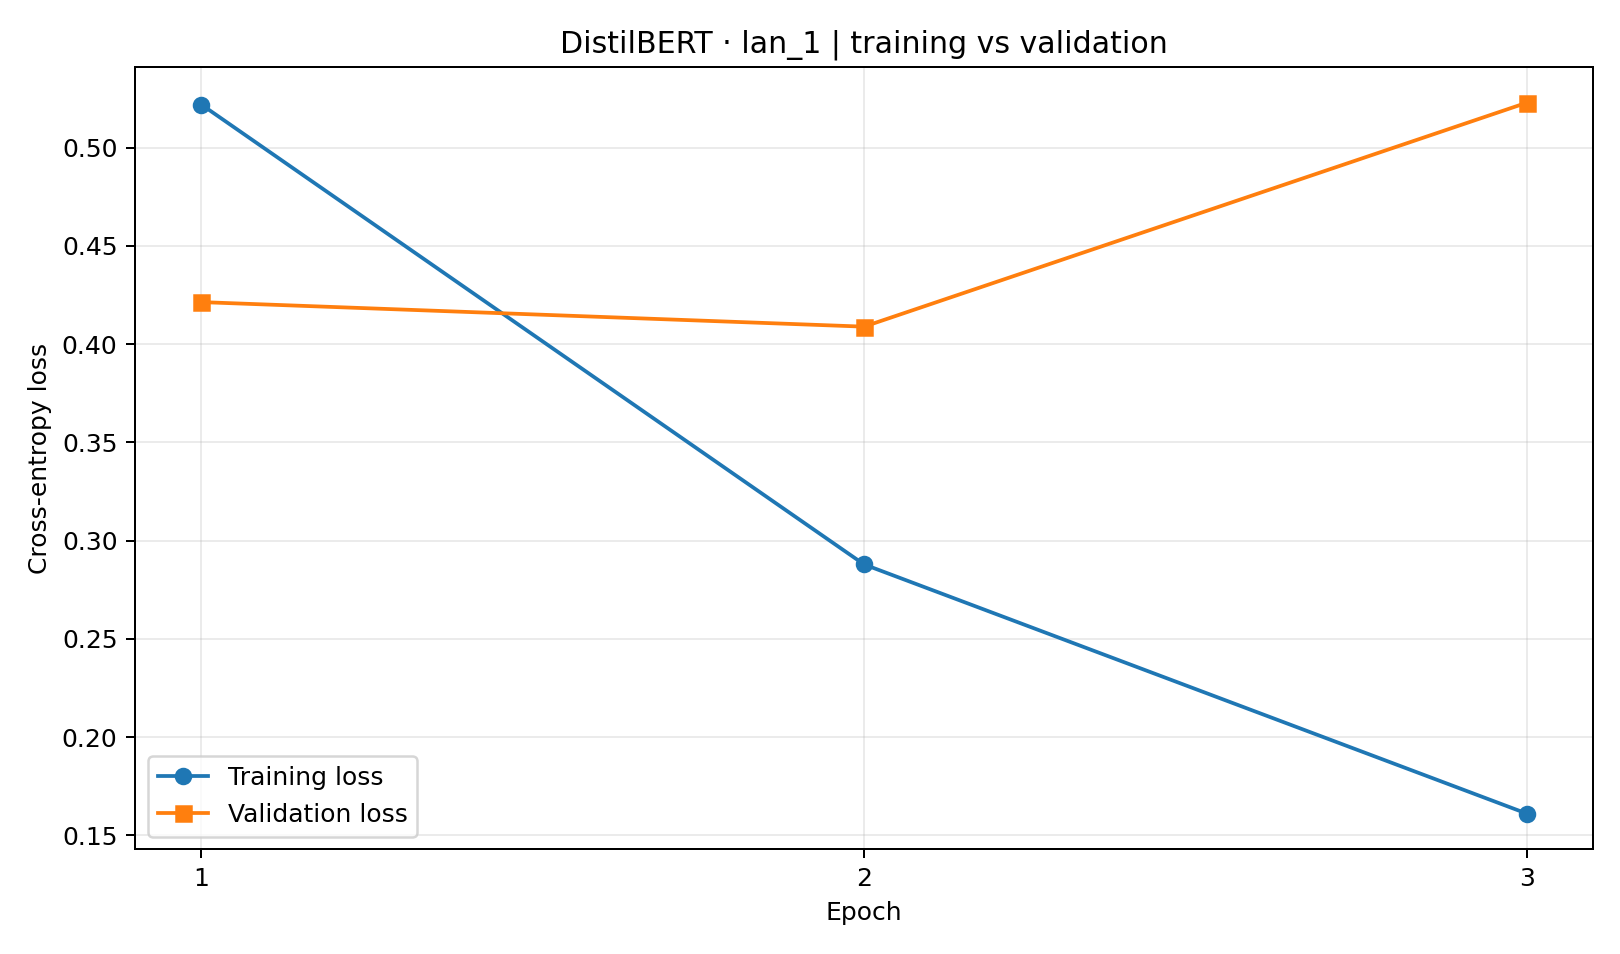

**validation_scores.png**

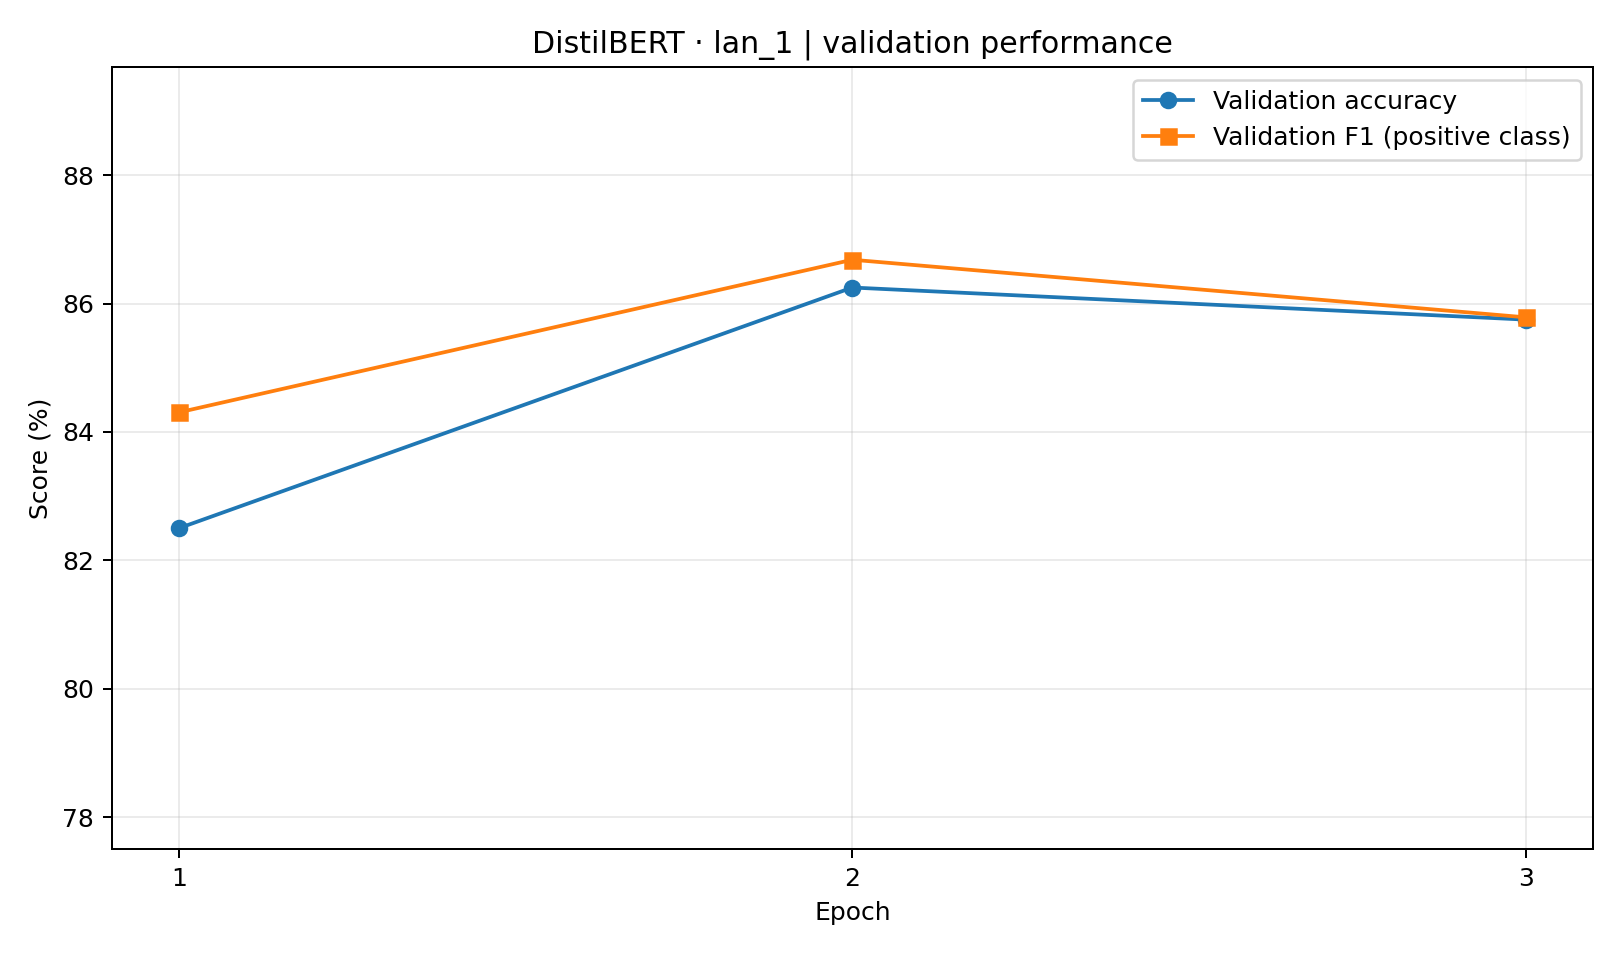

**confusion_matrix.png**

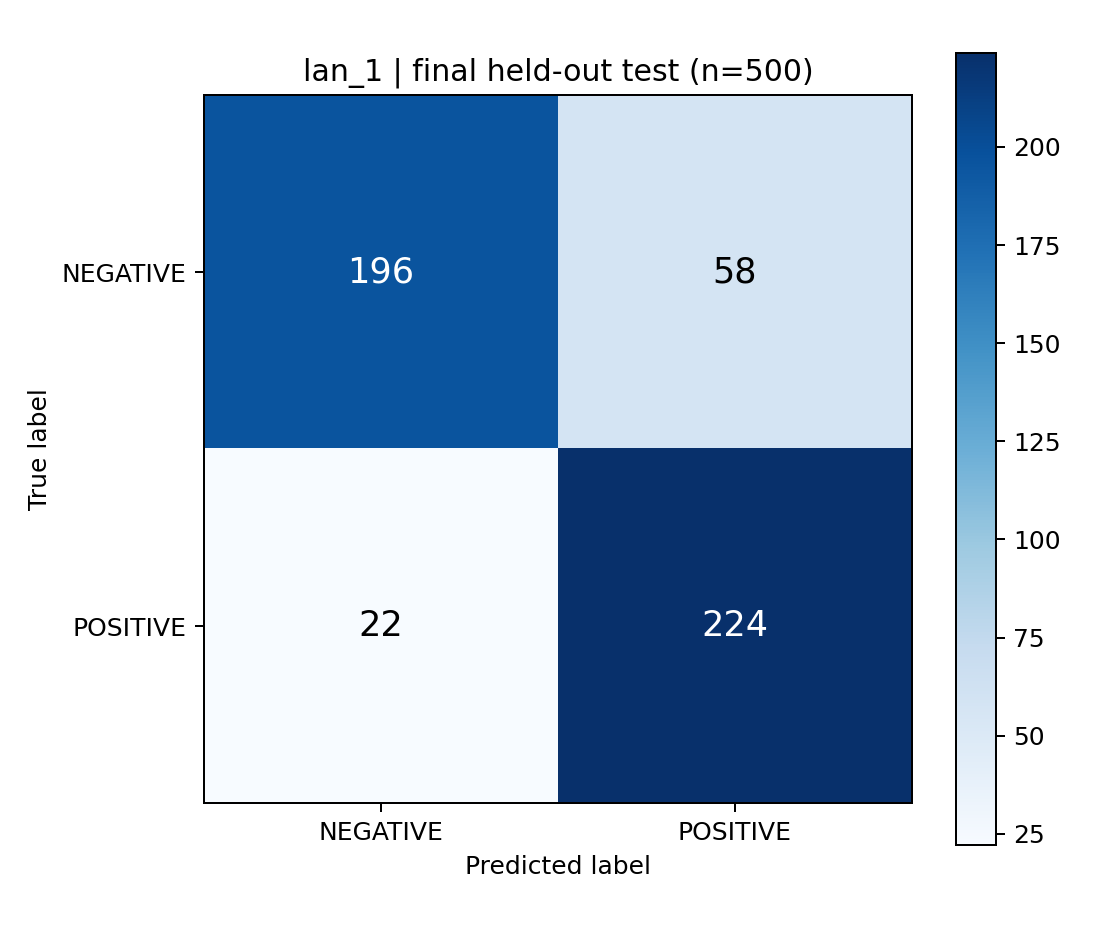

In [7]:
images = ROOT / 'visualization' / RUN
for name in ['loss.png','validation_scores.png','confusion_matrix.png']:
    p = images / name
    if p.exists():
        display(Markdown('**'+name+'**'))
        display(Image(filename=str(p)))
    else: print('Not generated:',name)


## 8. Interpretation and limitations

Complete this part **after reviewing real metrics**:

1. Did validation F1 improve and is the model under-/overfitting?
2. Which class has lower recall and what are FN/FP?
3. What does token truncation (max 128) mean for long reviews?
4. Were hyperparameters chosen without inspecting the final test?
5. Can results from a 2,000-sample, single-seed run generalize to full IMDb or another domain? **Not necessarily.**

**Conclusion:** [add grounded quantitative summary citing `test_metrics.json`].
-----

**1. Validation performance and overfitting**

Validation F1 increased from 84.30% at epoch 1 to 86.68% at epoch 2, before decreasing to 85.79% at epoch 3. Meanwhile, training loss decreased from 0.5219 to 0.1611, whereas validation loss increased to 0.5228 at epoch 3. These results suggest potential overfitting. Epoch 2 was selected as the best checkpoint based on validation F1.

**2. Classification errors and class performance**

On the final test set, the model achieved higher recall for POSITIVE reviews (91.06%) than for NEGATIVE reviews (77.17%).

The confusion matrix shows:

- 196 correctly classified NEGATIVE reviews.
- 224 correctly classified POSITIVE reviews.
- 58 NEGATIVE reviews incorrectly classified as POSITIVE (false positives).
- 22 POSITIVE reviews incorrectly classified as NEGATIVE (false negatives).

The model shows a tendency to predict POSITIVE for some genuinely NEGATIVE reviews.

**3. Token truncation limitations**

The maximum input length was set to 128 tokens to reduce computational and memory requirements. However, longer IMDb reviews may be truncated, potentially removing important sentiment information near the end of the text. This may affect classification performance.

**4. Hyperparameter selection and test independence**

The experiment used a learning rate of 2e-5, batch size of 8, and 3 training epochs. The best checkpoint was selected using validation F1.

The final test set was evaluated only after selecting the checkpoint. Test results were not used to choose the model or adjust hyperparameters.

**5. Generalization limitations**

The experiment used 2,000 training samples, 400 validation samples, and 500 test samples from IMDb, with a single random seed (42).

Because only a small subset of IMDb was used, the results may not represent performance on the full dataset. Additional experiments with different seeds, larger datasets, and reviews from other domains would be needed to assess robustness and generalization.

**Conclusion**

The fine-tuned DistilBERT model achieved **84.00% test accuracy**, **84.85% positive-class F1**, and **0.9195 ROC-AUC** on 500 held-out IMDb reviews.

Compared with the zero-shot SST-2 baseline (81.80% accuracy and 81.39% F1), the fine-tuned model improved accuracy by **2.20 percentage points** and F1 by approximately **3.46 percentage points**.

Overall, the experiment demonstrates that fine-tuning a pretrained language model can improve sentiment classification performance on the selected IMDb subset. However, the observed overfitting indicators, limited dataset size, and single-seed evaluation should be considered when interpreting these results.